# Where the standard corrections stop describing our objects

Every POG scale factor is a data/simulation ratio of an efficiency *measured on a
particular kind of object*: muons from Z and J/$\psi$ decays, electrons from Z decays,
photons from Z $\to\mu\mu\gamma$, jets from QCD events. A scale factor transfers to
another analysis only if that analysis selects objects of the same kind. The lepton
jets are not of that kind: their constituents are displaced, collimated, and often
reconstructed by algorithms (DSA muons) or as objects (photons from displaced
electrons) that the POG measurements do not cover.

This notebook compares the lepton-jet constituents with the objects the corrections
were measured on, over the whole signal grid, and lists where the corrections do and
do not apply. Everything is read from the `corrections_study` histograms of the
Condor campaign (README, "The Condor campaign"); simulation only.

In [1]:
import os, sys, warnings
import numpy as np
import hist
import matplotlib.pyplot as plt
import mplhep as hep
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import corrections, utilities
from sidm.studies.corrections import corrections_study as study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
print("campaign outputs:", study.CAMPAIGN_DIR)

campaign outputs: /store/user/scampbel/sidm_coffea_outputs/corrections_v1


## Samples

The plots compare three lifetimes of $m_\Phi$ = 500 GeV, $m_{Z_d}$ = 1.2 GeV,
$c\tau$ = 0.019, 1.9 and 19 mm, with DY muons in the Z $\to\mu\mu$ control region. The
signal is taken at the `base` selection (trigger, vertex, two muons above 26 GeV, two
lepton jets), before the isolation and displacement requirements of the SR, so that
the comparison is not shaped by the cuts whose corrections are in question. The
grid plots repeat each number for all 180 points against the median generator-level
$L_{xy}$ of the dark photons.

In [2]:
LIFETIMES = {"0p019mm": "0.019 mm", "1p9mm": "1.9 mm", "19p0mm": "19 mm"}
LT_COLORS = dict(zip(LIFETIMES, [BLUE, ORANGE, AQUA]))
DY, ZCR = "DYJetsToMuMu_M50", "Z_to_mumu_control_region"
SIGNALS = study.signal_points()
LXY = study.median_lxy()
out = study.load(SIGNALS + [DY])
REPS = [f"{fs}_500GeV_1p2GeV_{lt}" for fs in study.FINAL_STATES for lt in LIFETIMES]

def hists(sample, name, channel="base", syst="nominal"):
    return out[sample]["hists"][name][{"channel": channel, "syst": syst}]

def dy(name):
    return hists(DY, name, ZCR)

# grid plots: one panel per final state, colour = m_Phi, marker = m_Zd
MASSES = sorted({study.parse_point(s)["m_phi"] for s in SIGNALS})
MASS_COLORS = dict(zip(MASSES, plt.get_cmap("viridis")(np.linspace(0, 0.9, len(MASSES)))))
ZD_MARKERS = {0.25: "o", 1.2: "s", 5.0: "^"}

def grid(values, ylabel, figname, reference=None, ylim=None, logy=False, label_at=(0.97, 0.05)):
    # values: {sample: number}; reference: (value, label) drawn as a line, or
    # written in the panel when it is outside ylim; label_at places the final state
    fig, axs = plt.subplots(1, 2, figsize=(20, 7.5), sharey=True)
    for ax, fs in zip(axs, study.FINAL_STATES):
        for s, v in values.items():
            p = study.parse_point(s)
            if p["final_state"] != fs:
                continue
            ax.scatter(LXY[s], v, color=MASS_COLORS[p["m_phi"]], marker=ZD_MARKERS[p["m_zd"]], s=70,
                       edgecolor="none")
        if reference and ylim and not ylim[0] <= reference[0] <= ylim[1]:
            ax.text(0.03, 0.05, f"{reference[1]}: {reference[0]:.1f}", transform=ax.transAxes, color=GRAY,
                    fontsize=18)
        elif reference:
            ax.axhline(reference[0], color=GRAY, lw=2, ls="--")
            ax.text(0.03, reference[0], reference[1], transform=ax.get_yaxis_transform(), color=GRAY,
                    fontsize=16, va="bottom")
        ax.set_xscale("log")
        ax.set_xlabel(r"median $L_{xy}$ of the dark photons (cm)")
        ax.text(*label_at, fs, transform=ax.transAxes, ha="right" if label_at[0] > 0.5 else "left", fontsize=22)
        if logy:
            ax.set_yscale("log")
        if ylim:
            ax.set_ylim(*ylim)
    axs[0].set_ylabel(ylabel)
    handles = [Line2D([], [], color=MASS_COLORS[m], marker="o", ls="none", ms=10,
                      label=rf"$m_\Phi$ = {m:g} GeV") for m in MASSES]
    handles += [Line2D([], [], color=GRAY, marker=mk, ls="none", ms=10, label=rf"$m_{{Z_d}}$ = {z:g} GeV")
                for z, mk in ZD_MARKERS.items()]
    fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=15, bbox_to_anchor=(0.5, 1.12))
    plt.tight_layout()
    study.cms_label(axs)
    study.save(fig, figname)
    plt.show()

for s in REPS:
    print(f"{s:30s} {study.raw(out[s], 'base'):7d} events at base, "
          f"{hists(s, 'lj_pfMuon_tnp_phase_space').sum().value / hists(s, 'lj_n').sum().value:5.2f} PF muons per event")

2Mu2E_500GeV_1p2GeV_0p019mm      74466 events at base,  1.97 PF muons per event
2Mu2E_500GeV_1p2GeV_1p9mm        53062 events at base,  1.57 PF muons per event
2Mu2E_500GeV_1p2GeV_19p0mm        5562 events at base,  1.00 PF muons per event
4Mu_500GeV_1p2GeV_0p019mm       201939 events at base,  3.87 PF muons per event
4Mu_500GeV_1p2GeV_1p9mm         175045 events at base,  2.84 PF muons per event
4Mu_500GeV_1p2GeV_19p0mm         36440 events at base,  1.21 PF muons per event


## 1. PF muons: displaced and collimated

The Muon POG ID scale factors come from tag-and-probe on Z and J/$\psi$ decays. Their
probes are prompt (impact parameter of tens of microns), have a full pixel track, and
are far from any other muon. Three plots compare our lepton-jet PF muons with DY muons
in the Z control region (which are themselves lepton-jet constituents there):
transverse impact parameter, number of pixel hits, and the distance to the nearest
other muon of the same lepton jet.

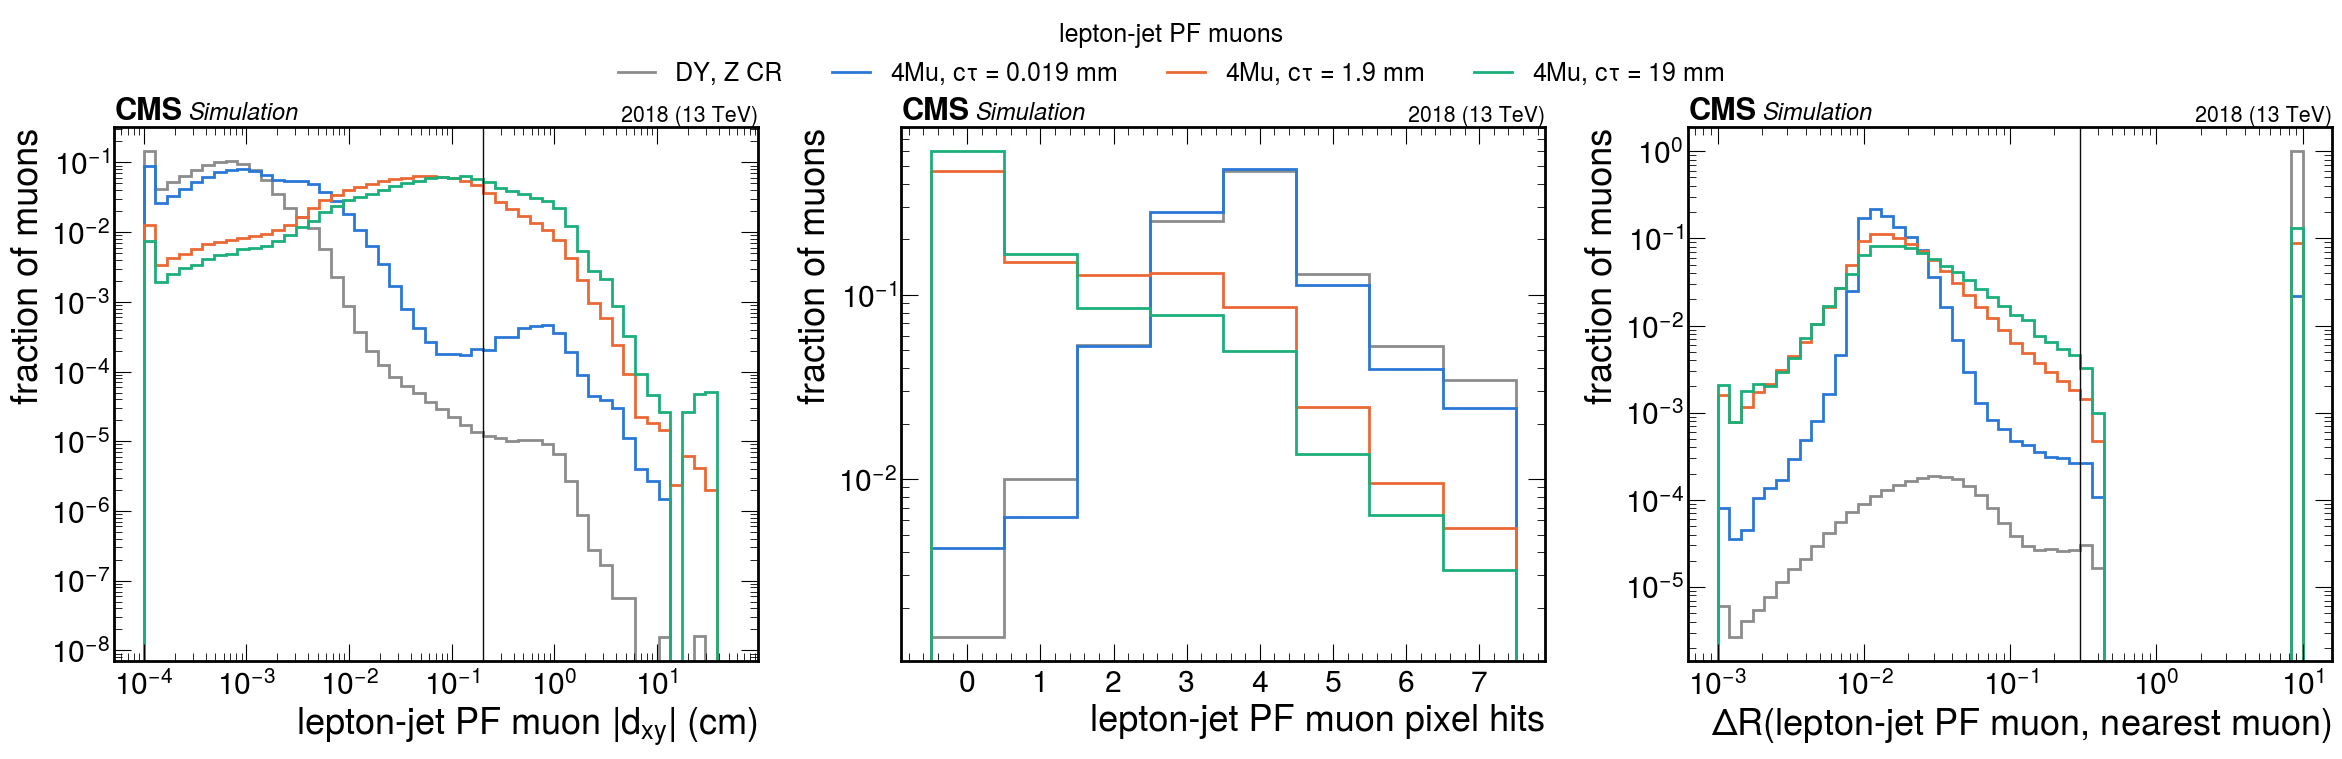

In [3]:
def compare(ax, name, final_state="4Mu", logy=True):
    # DY and the three lifetimes as fractions per bin; flow folded into the edge bins
    hep.histplot(study.fractions(dy(name)), ax=ax, color=GRAY, lw=2, yerr=False, label="DY, Z CR", flow="sum")
    for lt, lt_label in LIFETIMES.items():
        hep.histplot(study.fractions(hists(f"{final_state}_500GeV_1p2GeV_{lt}", name)), ax=ax,
                     color=LT_COLORS[lt], lw=2, yerr=False, label=rf"{final_state}, $c\tau$ = {lt_label}", flow="sum")
    ax.set_ylabel("fraction of muons")
    if logy:
        ax.set_yscale("log")

fig, axs = plt.subplots(1, 3, figsize=(24, 7))
compare(axs[0], "lj_pfMuon_absdxy_log")
axs[0].set_xscale("log")
axs[0].axvline(0.2, color=BLACK, lw=1)
compare(axs[1], "lj_pfMuon_pixelHits")
compare(axs[2], "lj_pfMuon_nearest_muon_dR")
axs[2].set_xscale("log")
axs[2].axvline(0.3, color=BLACK, lw=1)
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=18, bbox_to_anchor=(0.5, 1.13),
           title="lepton-jet PF muons", title_fontsize=18)
plt.tight_layout()
study.cms_label(axs)
study.save(fig, "applicability_muons")
plt.show()

The vertical lines mark two common boundaries of prompt-muon measurements: an impact
parameter below 0.2 cm, and no other muon within $\Delta R$ = 0.3 (the isolation
cone). A muon without a partner in its lepton jet is drawn at 9.9. The fraction of
lepton-jet PF muons outside each boundary, from the `lj_pfMuon_tnp_phase_space`
histogram (three booleans per muon):

sample                          |dxy|>0.2cm  <=2 pixel hits   dR<0.3    any
2Mu2E_500GeV_1p2GeV_0p019mm            0.2%           7.1%   99.7% 99.7%
2Mu2E_500GeV_1p2GeV_1p9mm             10.2%          74.0%   99.3% 99.7%
2Mu2E_500GeV_1p2GeV_19p0mm            20.4%          82.8%   96.7% 97.8%
4Mu_500GeV_1p2GeV_0p019mm              0.3%           6.3%   97.8% 98.0%
4Mu_500GeV_1p2GeV_1p9mm               14.2%          74.3%   91.0% 99.1%
4Mu_500GeV_1p2GeV_19p0mm              27.7%          85.0%   86.5% 99.0%
DY (Z CR)                              0.0%           6.5%    0.2%  6.7%
all points: 78.6 to 100.0% of the lepton-jet PF muons outside


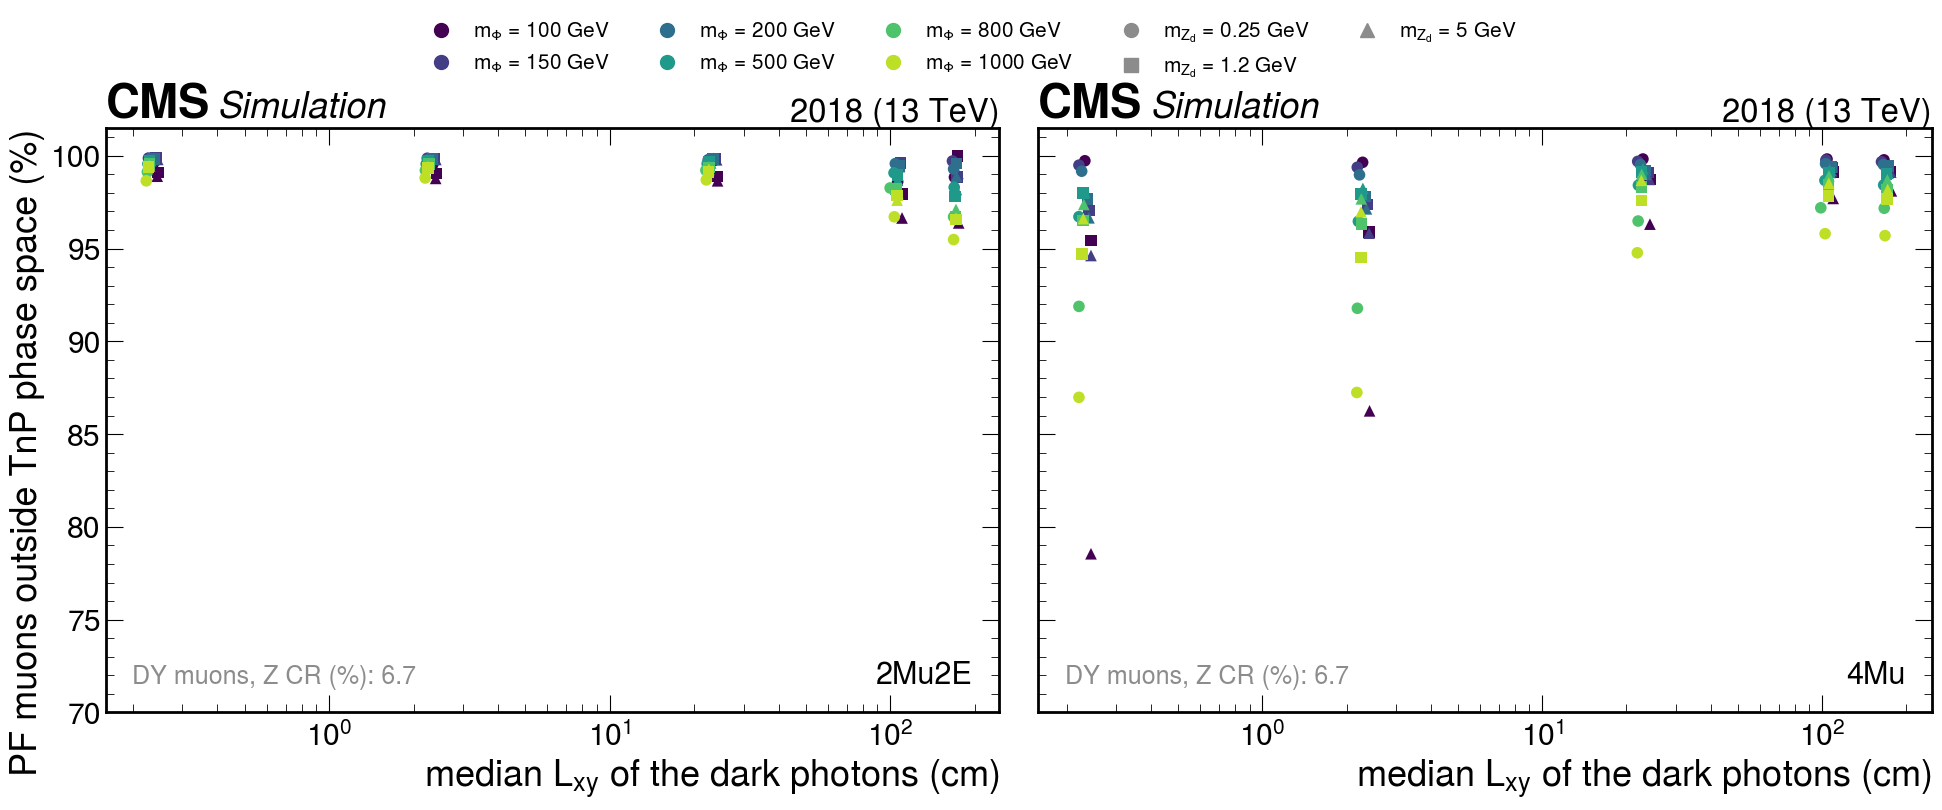

In [4]:
def muon_fractions(h):
    v = h.values()          # [displaced, few_pixel_hits, close_muon]
    total = v.sum()
    return {"|dxy|>0.2cm": v[1].sum() / total, "<=2 pixel hits": v[:, 1].sum() / total,
            "dR<0.3": v[:, :, 1].sum() / total, "any": 1 - v[0, 0, 0] / total}

print(f"{'sample':30s} {'|dxy|>0.2cm':>12s} {'<=2 pixel hits':>15s} {'dR<0.3':>8s} {'any':>6s}")
for s in REPS + ["DY (Z CR)"]:
    f = muon_fractions(dy("lj_pfMuon_tnp_phase_space") if s.startswith("DY") else hists(s, "lj_pfMuon_tnp_phase_space"))
    print(f"{s:30s}", "".join(f"{100 * v:{w}.1f}%" for v, w in zip(f.values(), (11, 14, 7, 5))))

outside = {s: 100 * muon_fractions(hists(s, "lj_pfMuon_tnp_phase_space"))["any"] for s in SIGNALS}
print(f"all points: {min(outside.values()):.1f} to {max(outside.values()):.1f}% of the lepton-jet PF muons outside")
grid(outside, "PF muons outside TnP phase space (%)", "applicability_muons_grid",
     reference=(100 * muon_fractions(dy("lj_pfMuon_tnp_phase_space"))["any"], "DY muons, Z CR (%)"),
     ylim=(70, 101.5))

At every lifetime of the benchmark, 98% or more of the lepton-jet PF muons are
outside at least one of these boundaries, against 6.7% of the DY muons, and over the
whole grid the fraction is 79 to 100%. The main reason is the same everywhere: 87 to
100% of the lepton-jet muons of the benchmark have another muon within
$\Delta R$ = 0.3, a configuration the Z tag-and-probe does not probe. Close-by muons
can lose efficiency in ways isolated ones cannot (shared segments in the muon
chambers, the arbitration that keeps one of two muons), and none of that is in the
SF. The lowest values, 79 to 92%, are 4Mu points at short lifetimes: $m_\Phi$ = 100 GeV
with $m_{Z_d}$ = 5 GeV, where the two muons open up the most, and
$m_\Phi$ = 800 to 1000 GeV with $m_{Z_d}$ = 0.25 GeV. The displacement comes on top with the
lifetime: at $c\tau$ = 1.9 mm three quarters of the muons have at most two pixel hits,
where the tracking efficiency has not been measured at all.

**Conclusion for muons.** The Loose ID SF is applied, since it is the best available
number and it is close to one, but its quoted uncertainty (a few per mille) describes
prompt, isolated muons. A dedicated measurement for close-by, displaced muons is
needed; until then this should carry an uncertainty of its own.

### DSA muons

The muon ID SFs exist for PF muons only. Displaced standalone (DSA) muons, which carry
the efficiency at long lifetimes, have no POG correction at all. From
`lj_muon_composition` (PF and DSA muons per lepton jet):

sample                           mu-LJs with a DSA muon   DSA muons only
2Mu2E_500GeV_1p2GeV_0p019mm                        4.1%             0.1%
2Mu2E_500GeV_1p2GeV_1p9mm                         36.8%             9.4%
2Mu2E_500GeV_1p2GeV_19p0mm                        63.9%            39.0%
4Mu_500GeV_1p2GeV_0p019mm                          3.5%             0.1%
4Mu_500GeV_1p2GeV_1p9mm                           34.4%            13.1%
4Mu_500GeV_1p2GeV_19p0mm                          73.7%            59.2%


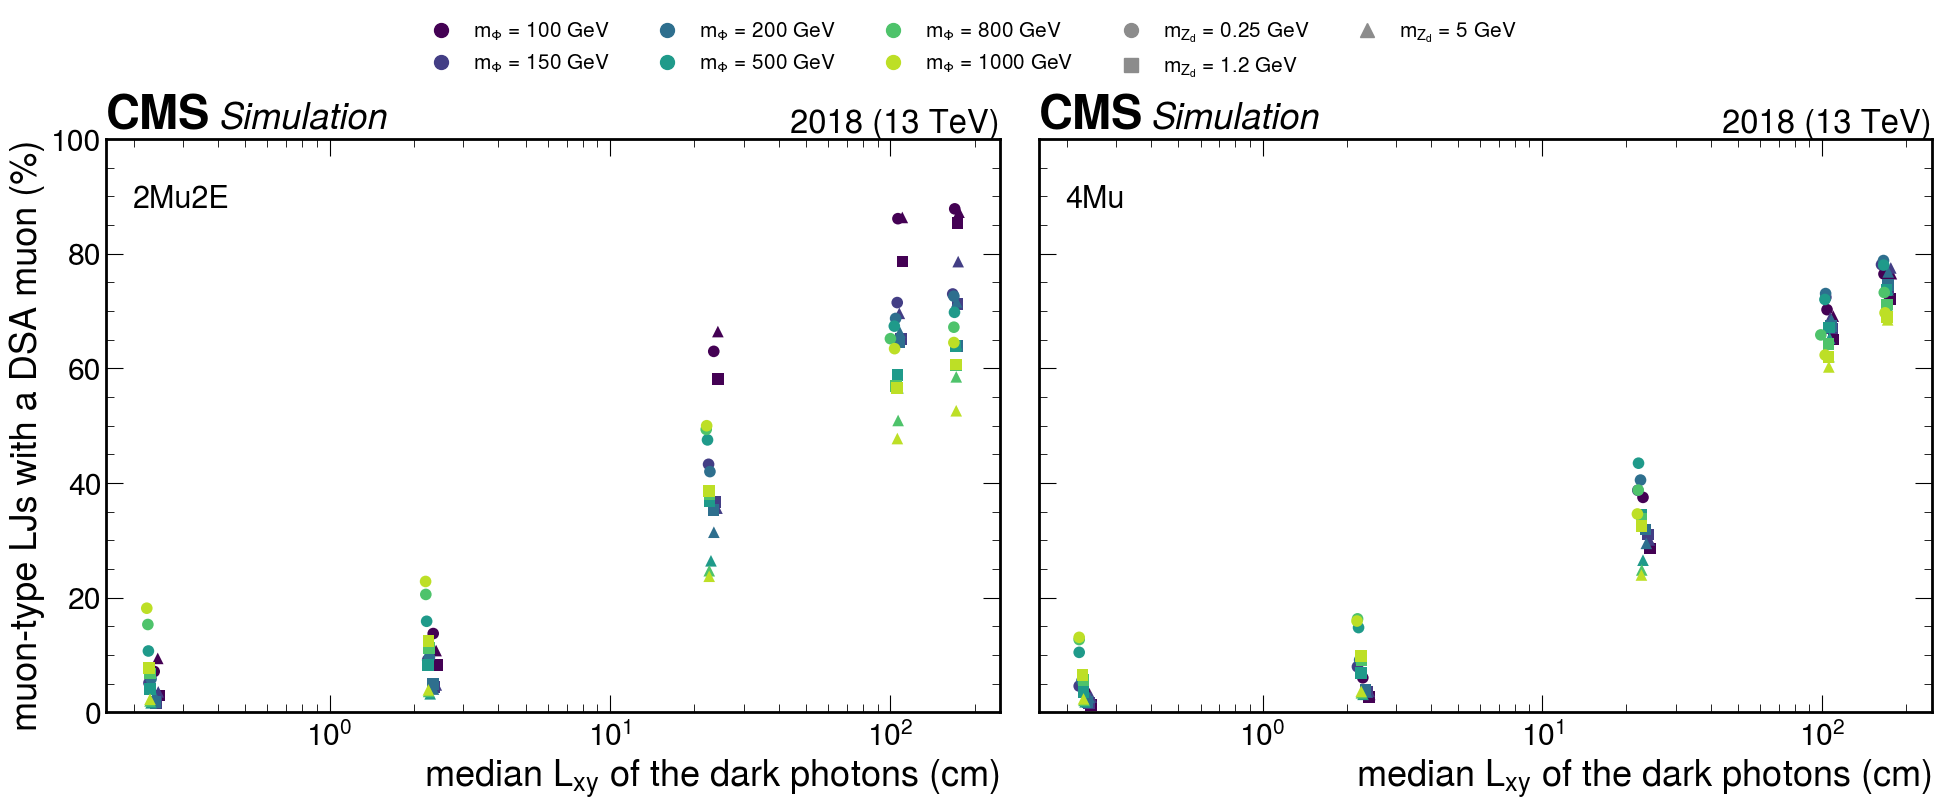

In [5]:
def dsa_shares(h):
    v = h.values(flow=True)            # [pf, dsa], index 1 is zero, 0 is underflow
    mu_lj = v.sum() - v[:2, :2].sum()  # at least one muon of either kind
    with_dsa = v[:, 2:].sum()
    dsa_only = v[:2, 2:].sum()
    return with_dsa / mu_lj, dsa_only / mu_lj

print(f"{'sample':30s} {'mu-LJs with a DSA muon':>24s} {'DSA muons only':>16s}")
for s in REPS:
    a, b = dsa_shares(hists(s, "lj_muon_composition"))
    print(f"{s:30s} {100 * a:23.1f}% {100 * b:15.1f}%")
with_dsa = {s: 100 * dsa_shares(hists(s, "lj_muon_composition"))[0] for s in SIGNALS}
grid(with_dsa, "muon-type LJs with a DSA muon (%)", "applicability_dsa_grid", ylim=(0, 100),
     label_at=(0.03, 0.88))

The DSA share rises steeply with the decay length, in the same way for every mass:
1 to 23% of the muon-type lepton jets contain a DSA muon for a median $L_{xy}$ below
5 cm, 24 to 66% between 5 and 50 cm, and 48 to 88% beyond, where 40 to 60% of the muon
lepton jets of the benchmark are made of DSA muons alone. For long lifetimes
a large part of the muon efficiency is therefore not covered by any standard
correction. Displaced-muon analyses measure it themselves, e.g. with cosmic muons or
with J/$\psi$ and Z tag-and-probe on standalone tracks. The framework is ready for it:
a measured SF goes into a correctionlib file and is attached to the `displaced ID` cut
in `corrections.yaml` (tutorial section 9c).

## 2. Electrons: an ID the SFs were not measured for

The EGM ID SFs are measured for the cut-based and MVA working points on prompt
electrons. Our lepton-jet electrons pass a custom selection, so the closest standard
SF would be that of `mvaFall17V2noIso_WP90`. From `lj_electron_id`:

In [6]:
def electron_fractions(h):
    v = h.values()      # [wp90, wp80, missing_hits]
    total = v.sum()
    return v[1].sum() / total, v[:, 1].sum() / total, v[:, :, 1].sum() / total

print(f"{'sample':30s} {'pass wp90noiso':>15s} {'pass wp80noiso':>15s} {'missing hits>=1':>16s}")
for s in REPS:
    if s.startswith("2Mu2E"):
        print(f"{s:30s}", "".join(f"{100 * v:14.1f}%" for v in electron_fractions(hists(s, "lj_electron_id"))))
wp90 = {s: 100 * electron_fractions(hists(s, "lj_electron_id"))[0] for s in SIGNALS if s.startswith("2Mu2E")}
print(f"all 2Mu2E points: {min(wp90.values()):.1f} to {max(wp90.values()):.1f}% pass wp90noiso")

sample                          pass wp90noiso  pass wp80noiso  missing hits>=1
2Mu2E_500GeV_1p2GeV_0p019mm              57.3%          41.2%           5.8%
2Mu2E_500GeV_1p2GeV_1p9mm                31.3%          19.7%          67.2%
2Mu2E_500GeV_1p2GeV_19p0mm               24.1%          14.7%          68.2%
all 2Mu2E points: 14.6 to 87.2% pass wp90noiso


The lepton-jet electrons pass `mvaFall17V2noIso_WPL`, which has no EGM scale factor
(the file stops at `wp80noiso` and `wp90noiso`), and a scale factor cannot be carried
from one working point to another. Only 57% of the benchmark lepton-jet electrons
pass wp90noiso at the shortest lifetime and a quarter to a third at the longer ones
(15 to 87% over the grid), so its SF would describe a different population. The
reconstruction SF is applied (every reconstructed electron needs it, whatever the ID)
but it is measured on prompt electrons: two thirds of the displaced lepton-jet
electrons have missing inner hits, and their GSF seeding and tracking efficiency are
different. As for muons, it is applied as the best available number with a
provisional status.

## 3. Photons: mostly electrons from the dark photon

The photon pixel-veto SF is measured on photons from Z $\to\mu\mu\gamma$, i.e. on real
photons that leave no pixel seed. The distance from each lepton-jet photon to the
nearest generator electron and to the nearest generator photon tells which the
lepton-jet photons are:

sample                          gen electron within 0.1  gen photon within 0.1  photons per electron
2Mu2E_500GeV_1p2GeV_0p019mm                       54.3%                  48.3%                 0.02
2Mu2E_500GeV_1p2GeV_1p9mm                         98.4%                  14.5%                 1.68
2Mu2E_500GeV_1p2GeV_19p0mm                        97.6%                  14.7%                 4.88


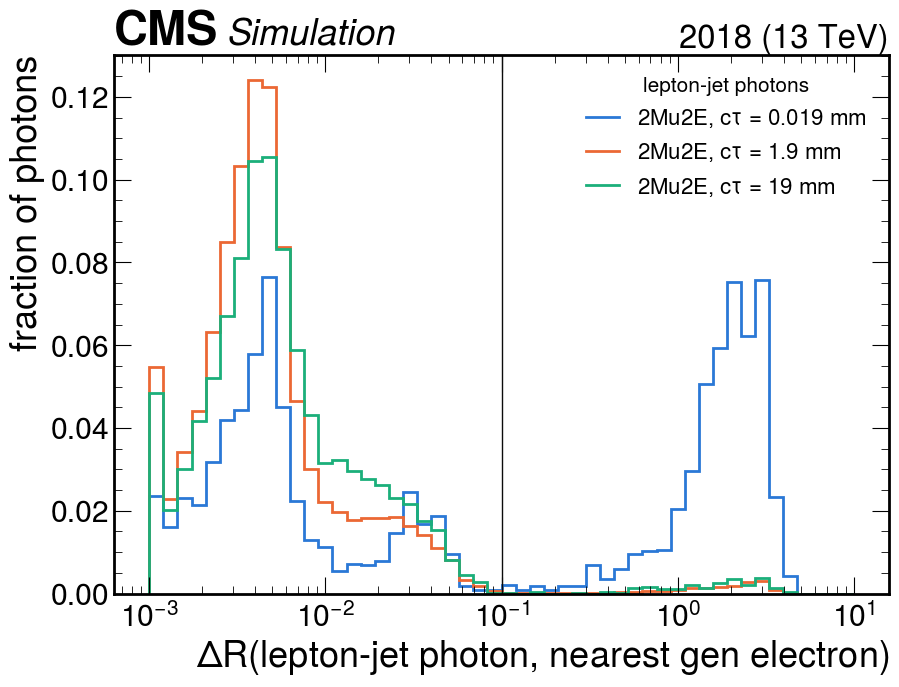

all 2Mu2E points: 44.5 to 99.7% of the lepton-jet photons within 0.1 of a gen electron


In [7]:
def within(h, edge=0.1):
    # fraction of entries below edge, which is a bin edge of the log axis
    i = np.argmin(np.abs(h.axes[0].edges - edge))   # bins 0..i-1 are below the edge
    v = h.values(flow=True)
    return v[:i + 1].sum() / v.sum()

print(f"{'sample':30s} {'gen electron within 0.1':>24s} {'gen photon within 0.1':>22s} {'photons per electron':>21s}")
for s in REPS:
    if s.startswith("2Mu2E"):
        n_ph = hists(s, "lj_photon_eCorr", syst="uncorrected").sum(flow=True).value
        n_el = hists(s, "lj_electron_eCorr", syst="uncorrected").sum(flow=True).value
        print(f"{s:30s} {100 * within(hists(s, 'lj_photon_genE_dR')):23.1f}% "
              f"{100 * within(hists(s, 'lj_photon_genPhoton_dR')):21.1f}% {n_ph / n_el:20.2f}")

fig, ax = plt.subplots(figsize=(10, 7))
for lt, lt_label in LIFETIMES.items():
    hep.histplot(study.fractions(hists(f"2Mu2E_500GeV_1p2GeV_{lt}", "lj_photon_genE_dR")), ax=ax,
                 color=LT_COLORS[lt], lw=2, yerr=False, label=rf"2Mu2E, $c\tau$ = {lt_label}", flow="sum")
ax.set_xscale("log")
ax.axvline(0.1, color=BLACK, lw=1)
ax.set_ylabel("fraction of photons")
ax.legend(fontsize=16, loc="upper right", title="lepton-jet photons", title_fontsize=15)
study.cms_label(ax)
study.save(fig, "applicability_photon_gen_match")
plt.show()

from_e = {s: 100 * within(hists(s, "lj_photon_genE_dR")) for s in SIGNALS if s.startswith("2Mu2E")}
print(f"all 2Mu2E points: {min(from_e.values()):.1f} to {max(from_e.values()):.1f}% of the lepton-jet photons within 0.1 of a gen electron")

For the displaced benchmark points ($c\tau$ = 1.9 and 19 mm, median $L_{xy}$ of 23 and
170 cm), 98% of the lepton-jet photons lie within $\Delta R$ < 0.1 of a generator
electron (97 to 100% over the grid for a median $L_{xy}$ between 5 and 50 cm, 89 to 100%
beyond), and they outnumber the lepton-jet electrons:
the more displaced the pair, the more often it is reconstructed as a photon (1.7
photons per electron at 1.9 mm, 4.9 at 19 mm, 0.02 at the shortest lifetime, where the
few photons are split between electrons and radiated photons).

The photon ID scale factors (and the custom ID we use has none anyway) and the
pixel-veto scale factor were measured with real photons. For an electron pair, whether
a pixel seed is found depends on where the dark photon decayed relative to the pixel
layers, a mechanism the real-photon measurement does not contain. At 0.96 in the
barrel and 0.88 in the endcap per photon, the pixel-veto SF would also be the largest
correction in the event weight. It is therefore **not** applied; the campaign
evaluates it as a monitored correction to show its effect (notebook 03).

## 4. Jets: the lepton jet is inside the jet it is isolated against

The lepton-jet isolation is the energy of the nearest AK4 jet that is not leptons,
relative to the lepton jet: (jet energy / LJ energy) $\times$ (1 $-$ lepton fraction of
the jet). The jet energy is JEC-corrected in NanoAOD, and the JEC is a correction for
the calorimeter response to hadrons, derived on QCD jets. For a jet that is almost
entirely the lepton jet itself, it is the wrong correction. From
`lj_matched_jet_lepfrac_jec`:

4Mu_500GeV_1p2GeV_1p9mm: 93.7% of lepton jets have a matched jet


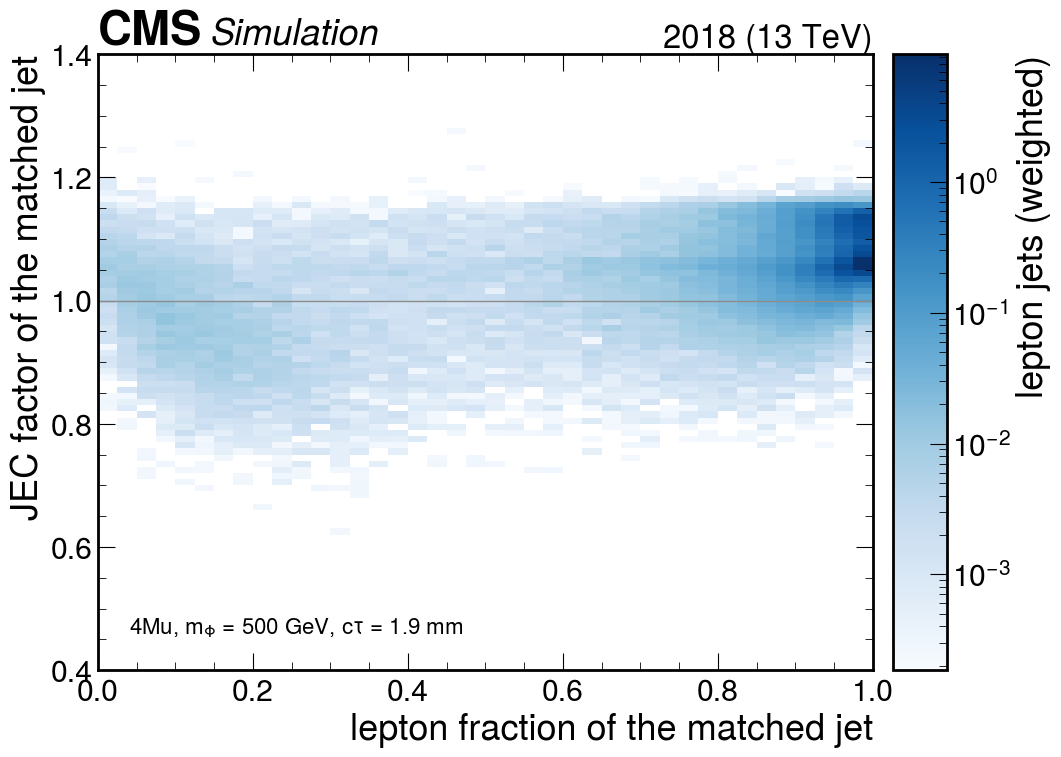

89.1% of matched jets have a lepton fraction above 0.9; their JEC factor: median 1.067, 16-84% range 1.048-1.124
all points: 46.1 to 98.1% of matched jets lepton-dominated


In [8]:
s = "4Mu_500GeV_1p2GeV_1p9mm"
h2 = hists(s, "lj_matched_jet_lepfrac_jec")
has_jet = hists(s, "lj_has_matched_jet").values()
print(f"{s}: {100 * has_jet[1] / has_jet.sum():.1f}% of lepton jets have a matched jet")

fig, ax = plt.subplots(figsize=(10, 8))
art = hep.hist2dplot(h2, ax=ax, norm=LogNorm(vmin=h2.values()[h2.values() > 0].min()), cmap="Blues", flow="none")
art.cbar.set_label("lepton jets (weighted)")
ax.axhline(1, color=GRAY, lw=1)
ax.text(0.04, 0.06, r"4Mu, $m_\Phi$ = 500 GeV, $c\tau$ = 1.9 mm", transform=ax.transAxes, fontsize=16)
study.cms_label(ax)
study.save(fig, "applicability_jec_lepton_fraction")
plt.show()

def lepton_dominated(h2):
    # lepton fraction >= 0.9 (overflow included: the fractions sum to one up to rounding)
    v = h2.values(flow=True)
    i = np.argmin(np.abs(h2.axes["lepfrac"].edges - 0.9))
    jec = v[i + 1:].sum(axis=0)
    cdf = np.cumsum(jec) / jec.sum()
    edges = np.concatenate([[h2.axes["jec"].edges[0]], h2.axes["jec"].edges, [h2.axes["jec"].edges[-1]]])
    q = lambda p: np.interp(p, cdf, edges[1:])
    return v[i + 1:].sum() / v.sum(), q(0.5), q(0.16), q(0.84)

frac, med, lo, hi = lepton_dominated(h2)
print(f"{100 * frac:.1f}% of matched jets have a lepton fraction above 0.9; their JEC factor: median {med:.3f}, "
      f"16-84% range {lo:.3f}-{hi:.3f}")
dominated = {s: 100 * lepton_dominated(hists(s, "lj_matched_jet_lepfrac_jec"))[0] for s in SIGNALS}
print(f"all points: {min(dominated.values()):.1f} to {max(dominated.values()):.1f}% of matched jets lepton-dominated")

Nine in ten matched jets of the benchmark are almost nothing but the lepton jet
itself (lepton fraction above 0.9; 46 to 98% over the grid, more at high mass), and
the JEC scales their energy up by about 7% (5 to 12% for the central 68%): a
correction for the response to hadrons, applied to leptons. NanoAOD's energy
fractions are fractions of the *raw* jet energy, so the isolation mixes a corrected
energy with raw fractions.

Now the isolation of each lepton jet computed five ways: as the analysis does
(`analysis`), with the raw instead of the corrected jet energy (`raw`), with the jet
shifted by its JES uncertainty (`jes_up`, `jes_down`), and with the JER smearing that
NanoAOD does not apply (`jer`). The SR asks for an isolation below 0.1 (muon-type) or
0.2 (egamma-type). The `lj_isolation_<variant>_flips` histograms count the lepton jets
whose pass/fail decision changes.

sample                         variant    mu-LJ pass  egm-LJ pass  LJs that flip
2Mu2E_500GeV_1p2GeV_0p019mm    analysis        95.6%        91.6%          0.00%
                               raw             96.1%        91.8%          0.35%
                               jes_up          95.6%        91.6%          0.06%
                               jes_down        95.7%        91.6%          0.06%
                               jer             95.5%        91.5%          0.10%
2Mu2E_500GeV_1p2GeV_1p9mm      analysis        95.9%        88.7%          0.00%
                               raw             96.2%        89.1%          0.42%
                               jes_up          95.8%        88.7%          0.09%
                               jes_down        96.0%        88.8%          0.09%
                               jer             95.8%        88.7%          0.15%
2Mu2E_500GeV_1p2GeV_19p0mm     analysis        90.4%        92.8%          0.00%
                            

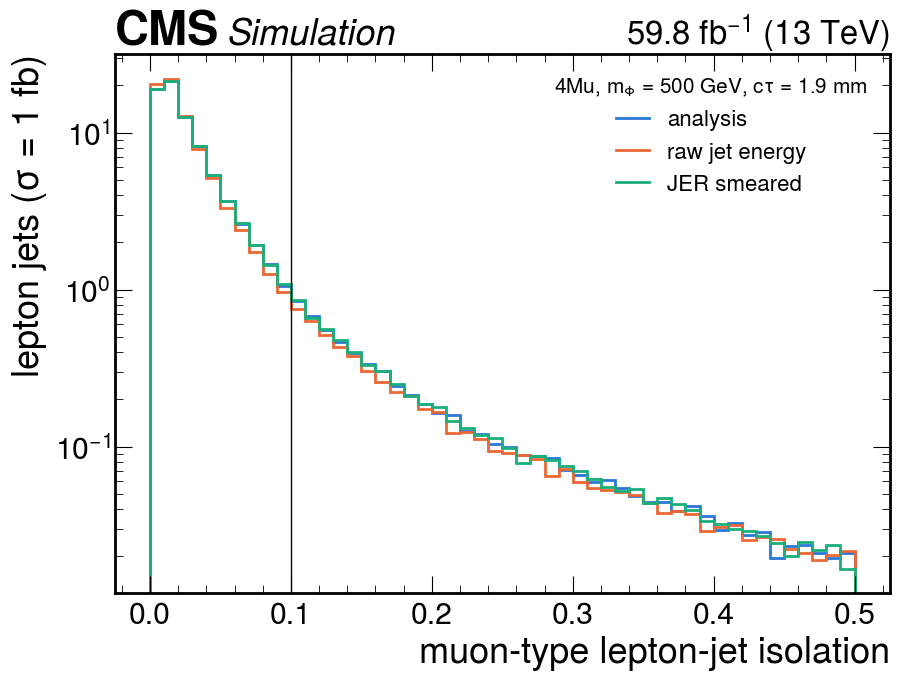

all points, raw     : 0.14 to 2.59% of lepton jets flip
all points, jes_up  : 0.00 to 1.09% of lepton jets flip
all points, jes_down: 0.02 to 1.18% of lepton jets flip
all points, jer     : 0.00 to 1.30% of lepton jets flip


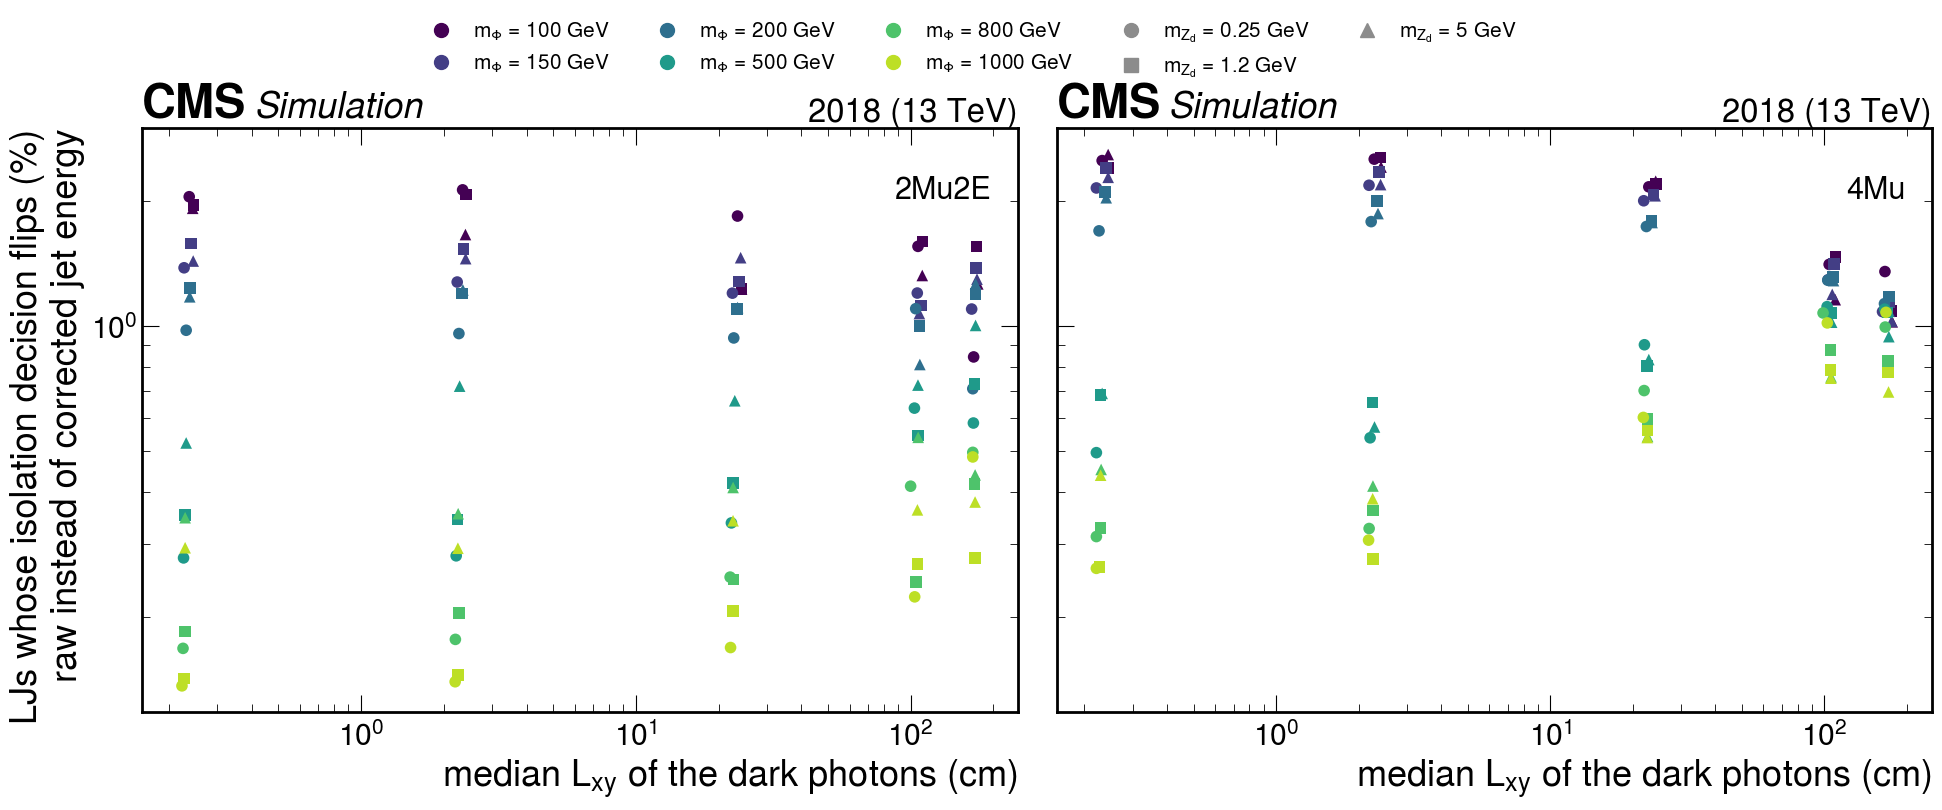

In [9]:
VARIANTS = ["raw", "jes_up", "jes_down", "jer"]

def isolation_table(s):
    rows = {}
    for v in VARIANTS:
        f = hists(s, f"lj_isolation_{v}_flips").values()   # [is_mu, pass_analysis, pass_variant]
        rows[v] = {"mu_pass": f[1, :, 1].sum() / f[1].sum(), "egm_pass": f[0, :, 1].sum() / max(f[0].sum(), 1e-300),
                   "flips": (f[:, 0, 1].sum() + f[:, 1, 0].sum()) / f.sum()}
        rows["analysis"] = {"mu_pass": f[1, 1].sum() / f[1].sum(), "egm_pass": f[0, 1].sum() / max(f[0].sum(), 1e-300),
                            "flips": 0.0}
    return rows

print(f"{'sample':30s} {'variant':10s} {'mu-LJ pass':>10s} {'egm-LJ pass':>12s} {'LJs that flip':>14s}")
for s in REPS:
    rows = isolation_table(s)
    for i, v in enumerate(["analysis"] + VARIANTS):
        r = rows[v]
        egm = f"{100 * r['egm_pass']:11.1f}%" if s.startswith("2Mu2E") else f"{'':>12s}"
        print(f"{s if i == 0 else '':30s} {v:10s} {100 * r['mu_pass']:9.1f}% {egm} {100 * r['flips']:13.2f}%")

s = "4Mu_500GeV_1p2GeV_1p9mm"
fig, ax = plt.subplots(figsize=(10, 7))
for v, color, label in [("analysis", BLUE, "analysis"), ("raw", ORANGE, "raw jet energy"), ("jer", AQUA, "JER smeared")]:
    hep.histplot(hists(s, f"lj_isolation_{v}")[{"is_mu": True}], ax=ax, color=color, lw=2, yerr=False,
                 label=label, flow="none")
ax.axvline(0.1, color=BLACK, lw=1)
ax.set_yscale("log")
ax.set_xlabel("muon-type lepton-jet isolation")
ax.set_ylabel(r"lepton jets ($\sigma$ = 1 fb)")
ax.legend(fontsize=16, title=r"4Mu, $m_\Phi$ = 500 GeV, $c\tau$ = 1.9 mm", title_fontsize=15)
study.cms_label(ax, lumi=study.LUMI_2018)
study.save(fig, "applicability_isolation")
plt.show()

flips = {v: {s: 100 * isolation_table(s)[v]["flips"] for s in SIGNALS} for v in VARIANTS}
for v in VARIANTS:
    print(f"all points, {v:8s}: {min(flips[v].values()):.2f} to {max(flips[v].values()):.2f}% of lepton jets flip")
grid(flips["raw"], "LJs whose isolation decision flips (%)\nraw instead of corrected jet energy",
     "applicability_isolation_grid", logy=True, label_at=(0.97, 0.88))

Most lepton jets are far below the cut, so the definitions differ mostly in the tail.
Using the raw instead of the corrected jet energy changes the decision for 0.3 to 1.1%
of the benchmark lepton jets (0.1 to 2.6% over the grid, largest at low mass), the JER
smearing for 0.1 to 1.0%, and the JES variation for 0.1 to 0.4%. Two conclusions:

* **JER smearing and the JES variation** move the SR isolation decision for a small
  fraction of lepton jets; propagating them properly needs a rerun of the selection per
  variation (a shape systematic). The tools are in place
  (`Corrections.jer_smearing_factor`, `Corrections.jes_uncertainty`, and the
  `lj_isolation_<variant>` histograms), but the processor does not yet rerun the
  selection for object variations.
* **Raw versus corrected energy** is a definition choice rather than a systematic:
  the JEC should arguably not act on the leptons of the lepton jet. It should be
  decided together with how the isolation is validated in data.

## 6. Everything the selection asks for, and what covers it

| selection requirement | objects | standard correction | status |
|---|---|---|---|
| pileup profile | all MC | LUM pileup weights | **standard**, applied |
| L1 prefiring | events with muons | NanoAOD prefiring weight | **standard**, applied; DSA-only lepton jets are not included in the weight |
| dimuon triggers (`DoubleL2Mu23NoVtx_2Cha` and siblings) | events | none | **missing**: needs a trigger-efficiency measurement in data (orthogonal triggers, or the cosmic-seeded paths) |
| PF muon `looseID` | lepton-jet PF muons | MUO Loose ID (J/$\psi$ below 20 GeV, Z above) | **approximate**, applied: measured on prompt, isolated muons |
| PF muon tracking, displaced | lepton-jet PF muons | none for displaced tracks | **missing** |
| DSA `displacedID`, PF-DSA cross cleaning | DSA muons | none | **missing** |
| electron reconstruction | lepton-jet electrons | EGM Reco SF | **approximate**, applied: prompt electrons only |
| electron `mvaFall17V2noIso_WPL` | lepton-jet electrons | none (EGM stops at wp90noiso) | **missing** |
| photon custom cut-based ID | lepton-jet photons | none | **missing** |
| photon pixel-seed veto | lepton-jet photons | EGM pixel-veto SF | **not applicable**: measured on real photons, ours are electron pairs; monitored, not applied |
| lepton-jet isolation | matched AK4 jets | JEC already in NanoAOD; JES, JER tools | **open**: JEC on lepton-dominated jets, JES/JER need a per-variation rerun |
| b-tag veto/selection ($t\bar t$ CR) | jets | BTV DeepJet fixed-WP SFs | **standard**, tool provided; needs MC b-tag efficiencies before it can be applied |
| electron and photon energy | electrons, photons | already in NanoAOD | **standard**, nothing to do; scale variations empty in these ntuples |
| muon momentum scale | PF muons | Rochester (not in correctionlib for Run 2) | **open**, small at our momenta |